# Employee Attrition Prediction using Machine Learning

## Research Methods in Data Science and Artificial Intelligence


---

## Project Overview

This notebook presents the practical implementation of an employee attrition prediction project. The aim is to predict whether an employee is likely to leave an organisation using demographic, job-related and organisational features.

Employee attrition is a relevant problem in Human Resource Analytics because high turnover can increase recruitment costs, reduce productivity and cause loss of organisational knowledge. Therefore, predicting attrition can support data-driven HR decision-making.

This project treats attrition prediction as a binary classification problem. Several machine learning models are developed and compared, including Logistic Regression, Random Forest and Gradient Boosting. The project also investigates whether feature selection improves prediction performance.

The main hypotheses tested in this notebook are:

- **H1:** Machine learning models, especially ensemble-based models, will outperform a baseline Logistic Regression model.
- **H2:** Feature selection will improve model performance compared with using all available features.

## Data Loading

The dataset is downloaded from Kaggle and loaded into a Pandas DataFrame. The dataset contains employee-level records with both numerical and categorical variables.

The target variable is **Attrition**, which indicates whether an employee stayed or left the organisation.

In [ ]:
from google.colab import userdata
import os

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")


In [ ]:
#!/bin/bash
!kaggle datasets download stealthtechnologies/employee-attrition-dataset
!unzip -o "*.zip"

Dataset URL: https://www.kaggle.com/datasets/stealthtechnologies/employee-attrition-dataset
License(s): apache-2.0
employee-attrition-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  employee-attrition-dataset.zip
  inflating: test.csv                
  inflating: train.csv               


## Exploratory Data Analysis (EDA)

Exploratory Data Analysis is conducted to understand the structure and quality of the dataset before model development.

This stage includes checking the dataset size, data types, missing values, target class distribution and basic descriptive statistics. These steps help identify whether cleaning, encoding, scaling or class imbalance handling is required before training machine learning models.

In [ ]:
import pandas as pd

train_df = pd.read_csv("train.csv")
test_df = pd.read_csv("test.csv")


train_df.head(10)

,Employee ID,Age,Gender,Years at Company,Job Role,Monthly Income,Work-Life Balance,Job Satisfaction,Performance Rating,Number of Promotions,...,Number of Dependents,Job Level,Company Size,Company Tenure,Remote Work,Leadership Opportunities,Innovation Opportunities,Company Reputation,Employee Recognition,Attrition
0,8410,31,Male,19,Education,5390,Excellent,Medium,Average,2,...,0,Mid,Medium,89,No,No,No,Excellent,Medium,Stayed
1,64756,59,Female,4,Media,5534,Poor,High,Low,3,...,3,Mid,Medium,21,No,No,No,Fair,Low,Stayed
2,30257,24,Female,10,Healthcare,8159,Good,High,Low,0,...,3,Mid,Medium,74,No,No,No,Poor,Low,Stayed
3,65791,36,Female,7,Education,3989,Good,High,High,1,...,2,Mid,Small,50,Yes,No,No,Good,Medium,Stayed
4,65026,56,Male,41,Education,4821,Fair,Very High,Average,0,...,0,Senior,Medium,68,No,No,No,Fair,Medium,Stayed
5,24368,38,Female,3,Technology,9977,Fair,High,Below Average,3,...,0,Mid,Medium,47,No,No,Yes,Fair,High,Left
6,64970,47,Male,23,Education,3681,Fair,High,High,1,...,3,Entry,Small,93,No,No,No,Good,Medium,Left
7,36999,48,Male,16,Finance,11223,Excellent,Very High,High,2,...,4,Entry,Medium,88,No,No,No,Excellent,Low,Stayed
8,32714,57,Male,44,Education,3773,Good,Medium,High,1,...,4,Entry,Medium,75,No,No,No,Fair,Medium,Stayed
9,15944,24,Female,1,Healthcare,7319,Poor,High,Average,1,...,4,Entry,Large,45,No,No,Yes,Good,Low,Left


In [ ]:
train_df.shape

(59598, 24)

In [ ]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59598 entries, 0 to 59597
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Employee ID               59598 non-null  int64 
 1   Age                       59598 non-null  int64 
 2   Gender                    59598 non-null  object
 3   Years at Company          59598 non-null  int64 
 4   Job Role                  59598 non-null  object
 5   Monthly Income            59598 non-null  int64 
 6   Work-Life Balance         59598 non-null  object
 7   Job Satisfaction          59598 non-null  object
 8   Performance Rating        59598 non-null  object
 9   Number of Promotions      59598 non-null  int64 
 10  Overtime                  59598 non-null  object
 11  Distance from Home        59598 non-null  int64 
 12  Education Level           59598 non-null  object
 13  Marital Status            59598 non-null  object
 14  Number of Dependents  

In [ ]:
train_df.isnull().sum()

,0
Employee ID,0
Age,0
Gender,0
Years at Company,0
Job Role,0
Monthly Income,0
Work-Life Balance,0
Job Satisfaction,0
Performance Rating,0
Number of Promotions,0


The missing value analysis shows that there are no missing values in the dataset. Therefore, no imputation method is required. This simplifies the preprocessing stage and reduces the risk of introducing bias through estimated values.

In [ ]:
train_df['Attrition'].value_counts()

,count
Attrition,
Stayed,31260
Left,28338


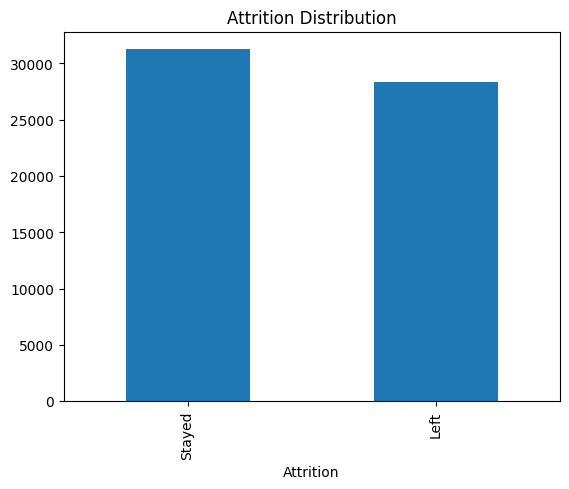

In [ ]:
import matplotlib.pyplot as plt

train_df['Attrition'].value_counts().plot(kind='bar')
plt.title("Attrition Distribution")
plt.show()

The target distribution shows that the dataset is relatively balanced, with 31,260 employees labelled as Stayed and 28,338 labelled as Left. Since the imbalance is not severe, SMOTE or other resampling techniques were not applied in this implementation.

In [ ]:
train_df.describe()

,Employee ID,Age,Years at Company,Monthly Income,Number of Promotions,Distance from Home,Number of Dependents,Company Tenure
count,59598.000000,59598.000000,59598.000000,59598.000000,59598.000000,59598.000000,59598.000000,59598.000000
mean,37227.118729,38.565875,15.753901,7302.397983,0.832578,50.007651,1.648075,55.758415
std,21519.150028,12.079673,11.245981,2151.457423,0.994991,28.466459,1.555689,25.411090
min,1.000000,18.000000,1.000000,1316.000000,0.000000,1.000000,0.000000,2.000000
25%,18580.250000,28.000000,7.000000,5658.000000,0.000000,25.000000,0.000000,36.000000
50%,37209.500000,39.000000,13.000000,7354.000000,1.000000,50.000000,1.000000,56.000000
75%,55876.750000,49.000000,23.000000,8880.000000,2.000000,75.000000,3.000000,76.000000
max,74498.000000,59.000000,51.000000,16149.000000,4.000000,99.000000,6.000000,128.000000


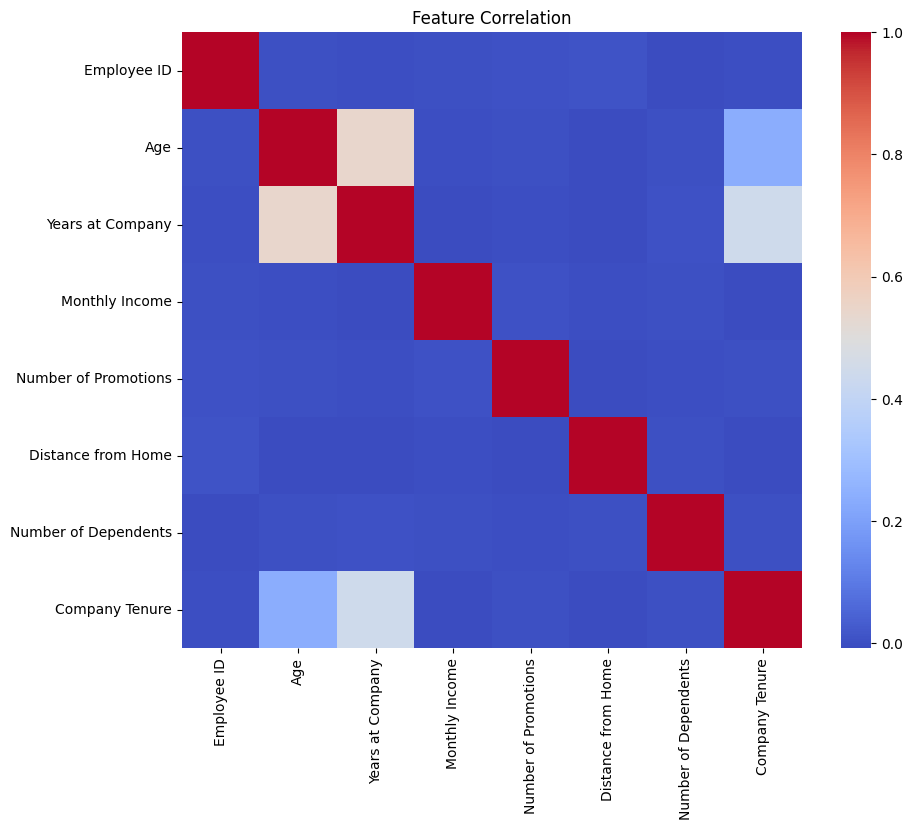

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

numeric_df = train_df.select_dtypes(include=['int64', 'float64'])
plt.figure(figsize=(10,8))
sns.heatmap(numeric_df.corr(), cmap='coolwarm')
plt.title("Feature Correlation")
plt.show()

The correlation heatmap provides an overview of relationships between numerical variables. Since most categorical variables still require encoding, this heatmap is mainly used as an initial exploratory step rather than a complete feature relationship analysis.

In [ ]:
train_df = train_df.drop("Employee ID", axis=1)
test_df = test_df.drop('Employee ID', axis=1)

In [ ]:
train_df['Attrition'].value_counts()

,count
Attrition,
Stayed,31260
Left,28338


## Data Preprocessing

The preprocessing stage prepares the dataset for machine learning algorithms. The Employee ID column is removed because it does not provide useful predictive information.

The target variable (Attrition) is converted into binary values, and categorical variables are transformed using One-Hot Encoding to avoid introducing artificial ordinal relationships between categories. Since the dataset already contains separate training and testing files, no additional train-test split is applied.

Feature scaling is also performed to maintain consistency across models and improve the performance of scale-sensitive algorithms such as Logistic Regression.

In [ ]:
train_df['Attrition'] = train_df['Attrition'].map({'Stayed': 0, 'Left': 1})
test_df['Attrition'] = test_df['Attrition'].map({'Stayed': 0, 'Left': 1})

In [ ]:
X_train = train_df.drop('Attrition', axis=1)
y_train = train_df['Attrition']

X_test = test_df.drop('Attrition', axis=1)
y_test = test_df['Attrition']

In [ ]:
X_train = pd.get_dummies(X_train, drop_first=True)
X_test = pd.get_dummies(X_test, drop_first=True)

X_train, X_test = X_train.align(
    X_test,
    join='left',
    axis=1,
    fill_value=0
)

In [ ]:
X_train_df = X_train.copy()
X_test_df = X_test.copy()

feature_names = X_train_df.columns

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_df)
X_test_scaled = scaler.transform(X_test_df)

## Model Training

Three machine learning models are trained and compared.

**Logistic Regression** is used as the baseline model because it is simple, interpretable and commonly used for binary classification problems.

**Random Forest** is used as an ensemble learning method that can capture non-linear relationships and provide feature importance scores.

**Gradient Boosting** is included because it builds sequential decision trees and often performs well on structured tabular datasets.

This comparison is designed to evaluate Hypothesis 1, which proposes that ensemble learning methods outperform Logistic Regression.

In [ ]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)

y_pred_rf = rf.predict(X_test_scaled)

In [ ]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train_scaled, y_train)

y_pred_gb = gb.predict(X_test_scaled)

## Model Evaluation

The models are evaluated using Accuracy, Precision, Recall, F1-score and ROC-AUC.

Accuracy shows the overall proportion of correct predictions. However, because employee attrition prediction involves two classes, F1-score and ROC-AUC are also important. F1-score balances Precision and Recall, while ROC-AUC measures how well the model separates employees who stayed from those who left across different classification thresholds.

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

def evaluate_model(name, model, X_test_data, y_test):
    y_pred = model.predict(X_test_data)
    y_proba = model.predict_proba(X_test_data)[:, 1]

    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    }

results = []

results.append(evaluate_model("Logistic Regression", lr, X_test_scaled, y_test))
results.append(evaluate_model("Random Forest", rf, X_test_scaled, y_test))
results.append(evaluate_model("Gradient Boosting", gb, X_test_scaled, y_test))

results_df = pd.DataFrame(results)
results_df.sort_values(by="F1-score", ascending=False)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Gradient Boosting,0.757852,0.744781,0.740757,0.742763,0.849794
0,Logistic Regression,0.755503,0.743288,0.736206,0.739730,0.845072
1,Random Forest,0.745772,0.734868,0.721701,0.728225,0.835600


## Model Improvement and Hyperparameter Tuning

After comparing the initial models, hyperparameter tuning is applied to Gradient Boosting because it achieved the best performance in the initial evaluation.

GridSearchCV is used to search for the best combination of selected hyperparameters. The tuning process uses cross-validation and F1-score as the optimisation metric. F1-score is selected because it provides a balanced measure of Precision and Recall.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

param_grid = {
    'n_estimators': [100, 150, 200],
    'learning_rate': [0.05, 0.1],
    'max_depth': [2, 3, 4]
}

gb_tuned = GradientBoostingClassifier(random_state=42)

grid_search = GridSearchCV(
    estimator=gb_tuned,
    param_grid=param_grid,
    scoring='f1',
    cv=3,
    n_jobs=-1
)

grid_search.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1-score:", grid_search.best_score_)

Best Parameters: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 200}
Best CV F1-score: 0.7460609114075131


In [ ]:
best_gb = grid_search.best_estimator_

y_pred_best_gb = best_gb.predict(X_test_scaled)
y_proba_best_gb = best_gb.predict_proba(X_test_scaled)[:, 1]

In [ ]:
results.append(evaluate_model("Tuned Gradient Boosting", best_gb, X_test_scaled, y_test))

results_df = pd.DataFrame(results)
results_df.sort_values(by="F1-score", ascending=False)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
3,Tuned Gradient Boosting,0.760805,0.747856,0.744027,0.745937,0.852354
2,Gradient Boosting,0.757852,0.744781,0.740757,0.742763,0.849794
0,Logistic Regression,0.755503,0.743288,0.736206,0.739730,0.845072
1,Random Forest,0.745772,0.734868,0.721701,0.728225,0.835600


## Feature Importance Analysis

Feature importance analysis is conducted to improve the interpretability of the model. In an HR context, prediction alone is not sufficient; it is also important to understand which factors contribute most strongly to attrition risk.

Analysing feature importance helps identify the variables that have the greatest influence on employee attrition predictions. Understanding these influential factors can provide more meaningful insights into employee behaviour and support more informed HR decision-making.

In [ ]:
feature_names = X_train_df.columns

importances = best_gb.feature_importances_

feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

feature_importance_df.head(10)

,Feature,Importance
27,Marital Status_Single,0.207489
29,Job Level_Senior,0.203520
32,Remote Work_Yes,0.136872
28,Job Level_Mid,0.067318
14,Work-Life Balance_Poor,0.054986
12,Work-Life Balance_Fair,0.049183
3,Number of Promotions,0.043377
4,Distance from Home,0.033122
5,Number of Dependents,0.032697
25,Education Level_PhD,0.032485


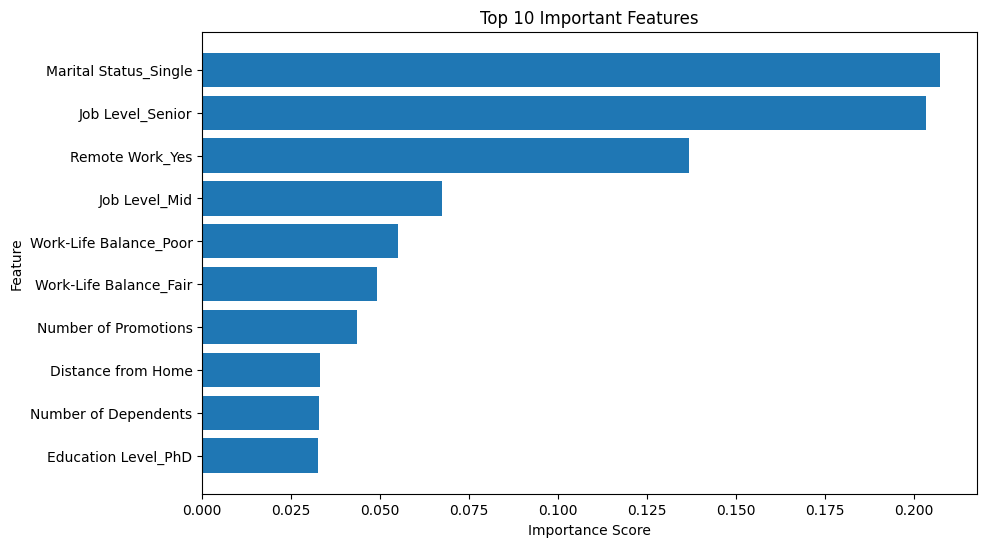

In [ ]:
top_10_features = feature_importance_df.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_10_features['Feature'], top_10_features['Importance'])
plt.xlabel("Importance Score")
plt.ylabel("Feature")
plt.title("Top 10 Important Features")
plt.gca().invert_yaxis()
plt.show()

The feature importance results indicate that Job Level, Marital Status, Remote Work, and Work-Life Balance were among the most influential features used by the model for prediction.

## Feature Selection

Feature selection is applied using the top 10 most important features identified from the Tuned Gradient Boosting model.
This experiment was performed to evaluate Hypothesis 2, which proposes that using a reduced feature set may improve predictive performance.

In [ ]:
top_features = feature_importance_df['Feature'].head(10)

X_train_selected = X_train_df[top_features]
X_test_selected = X_test_df[top_features]

In [ ]:
gb_selected_tuned = GradientBoostingClassifier(
    learning_rate=0.1,
    max_depth=3,
    n_estimators=200,
    random_state=42
)

gb_selected_tuned.fit(X_train_selected, y_train)

y_pred_selected = gb_selected_tuned.predict(X_test_selected)

y_proba_selected = gb_selected_tuned.predict_proba(X_test_selected)[:,1]

results.append(
    evaluate_model(
        "Tuned Gradient Boosting - Selected Features",
        gb_selected_tuned,
        X_test_selected,
        y_test
    )
)

results_df = pd.DataFrame(results)
results_df.sort_values(by="F1-score", ascending=False)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
3,Tuned Gradient Boosting,0.760805,0.747856,0.744027,0.745937,0.852354
2,Gradient Boosting,0.757852,0.744781,0.740757,0.742763,0.849794
0,Logistic Regression,0.755503,0.743288,0.736206,0.739730,0.845072
1,Random Forest,0.745772,0.734868,0.721701,0.728225,0.835600
4,Tuned Gradient Boosting - Selected Features,0.743758,0.733169,0.718572,0.725797,0.831202


## Cross-Validation

Five-fold cross-validation was applied to evaluate the robustness of the Tuned Gradient Boosting model. The results help assess whether the model generalises consistently across different subsets of the data.

In [ ]:
from sklearn.model_selection import cross_val_score
import pandas as pd

cv_scores = cross_val_score(
    best_gb,
    X_train_scaled,
    y_train,
    cv=5,
    scoring='f1'
)

cv_results = pd.DataFrame({
    "Fold": [1,2,3,4,5],
    "F1-score": cv_scores
})

cv_results.loc["Mean"] = ["-", cv_scores.mean()]

cv_results

,Fold,F1-score
0,1,0.744264
1,2,0.741561
2,3,0.746897
3,4,0.741200
4,5,0.744932
Mean,-,0.743771


## ROC Curve Analysis

ROC curves are used to compare model discrimination performance. The Tuned Gradient Boosting model achieved the best results.

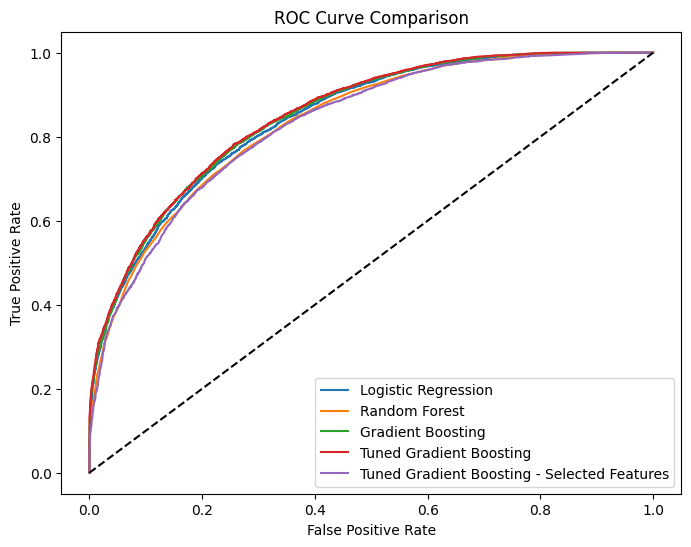

In [ ]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8,6))

for model, name, X_data in [
    (lr, "Logistic Regression", X_test_scaled),
    (rf, "Random Forest", X_test_scaled),
    (gb, "Gradient Boosting", X_test_scaled),
    (best_gb, "Tuned Gradient Boosting", X_test_scaled),
    (gb_selected_tuned, "Tuned Gradient Boosting - Selected Features", X_test_selected)
]:

    y_proba = model.predict_proba(X_data)[:,1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)

    plt.plot(fpr, tpr, label=name)

plt.plot([0,1], [0,1], 'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

plt.show()

## Confusion Matrix Analysis

The confusion matrix provides a detailed evaluation of the final Tuned Gradient Boosting model by showing correct and incorrect classifications for each class.

The results indicate balanced classification performance, suggesting that the model distinguishes reasonably well between employees who stayed and employees who left.

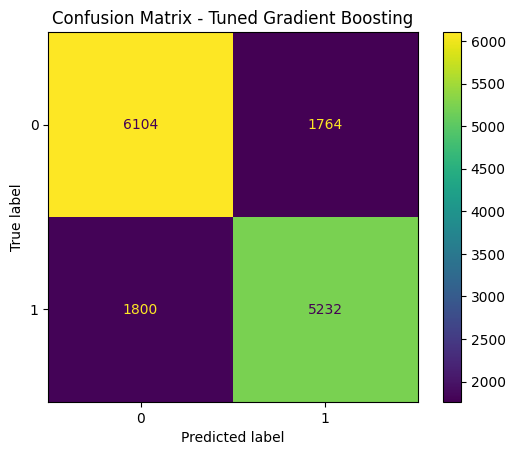

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_best_gb)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Tuned Gradient Boosting")
plt.show()